Se cunosc date despre angajatii unei companii, date salvate in fisierul "data/employees.csv".

1.
    a. Sa se stabileasca:

        ‣ numarul de angajati
        ‣ numar si tipul informatiilor (proprietatilor) detinute pentru un angajat
        ‣ numarul de angajati pentru care se detin date complete
        ‣ valorile minime, maxime, medii pentru fiecare proprietate
        ‣ in cazul proprietatilor nenumerice, cate valori posibile are fiecare astfel de proprietate
        ‣ daca sunt valori lipsa si cum se poate rezolva aceasta problema
        
    b. Sa se vizualizeze:

        ‣ distributia salariilor acestor angajati pe categorii de salar
        ‣ distributia salariilor acestor angajati pe categorii de salar si echipa din care fac parte
        ‣ angajatii care pot fi considerati "outlieri"
        

Display datas

In [2]:
import pandas as pd

def get_data_frame(path):
    '''
    Citeste si returneaza DataFrame-ul corespunzator fisierului csv specificat
    path: calea spre fisierul csv
    '''
    return pd.read_csv(path,delimiter=',', header='infer')

df_employees = get_data_frame('data/employees.csv')
df_employees

/tmp/ipykernel_49201/2201860125.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services
...,...,...,...,...,...,...,...,...
995,Henry,NaN,11/23/2014,6:09 AM,132483,16.655,False,Distribution
996,Phillip,Male,1/31/1984,6:30 AM,42392,19.675,False,Finance
997,Russell,Male,5/20/2013,12:39 PM,96914,1.421,False,Product
998,Larry,Male,4/20/2013,4:45 PM,60500,11.985,False,Business Development


Numarul de Angajat:

In [3]:
def get_noOfEmployees(path):
    '''
    Calculeaza numarul de angajati retinuti in fisierul csv specificat
    path: calea spre fisierul csv
    '''
    df_employees = get_data_frame(path)
    return len(df_employees)

def test_get_noOfEmployees():
    assert get_noOfEmployees('data/employees.csv') == 1000

noOfEmployees = get_noOfEmployees('data/employees.csv')
print('Numarul angajatilor: {}'.format(noOfEmployees))

Numarul angajatilor: 1000


Numarul si tipul proprietatilor detinute de un angajat:

In [8]:
import numpy as np

def get_nrColoaneSiColoaneNameAndType(path):
    '''
    Determina numarul de coloane si tipul fiecarei coloane
    path: calea spre fisierul csv
    '''
    df_employees = get_data_frame(path)
    noOfColumns = df_employees.shape[1]
    columns = []
    for column in df_employees.head():
        columns.append((column, df_employees[column].dtype))
    return noOfColumns, columns

def test_get_nrColoaneSiColoaneNameAndType():
    nr, cols = get_nrColoaneSiColoaneNameAndType('data/employees.csv')
    x = []
    assert nr == 8
    assert cols.__contains__(('First Name',np.object_))
    assert cols.__contains__(('Gender',np.object_))
    assert cols.__contains__(('Start Date',np.object_))
    assert cols.__contains__(('Last Login Time',np.object_))
    assert cols.__contains__(('Salary',np.int64))
    assert cols.__contains__(('Bonus %',np.float64))
    assert cols.__contains__(('Senior Management',np.object_))
    assert cols.__contains__(('Team',np.object_))

nr, cols = get_nrColoaneSiColoaneNameAndType('data/employees.csv')
print('Nr coloane: {}\n'.format(nr))
for col, type in cols:
    print('Coloana: {}\ntype: {}\n'.format(col, type))

Nr coloane: 8

Coloana: First Name
type: object

Coloana: Gender
type: object

Coloana: Start Date
type: object

Coloana: Last Login Time
type: object

Coloana: Salary
type: int64

Coloana: Bonus %
type: float64

Coloana: Senior Management
type: object

Coloana: Team
type: object



Numarul de angajati pentru care se detin date complete:

In [12]:
def get_NrAngajatiDateComplete(path):
    '''
    Calculeaza numarul de angajati pentru care se retin date complete
    path: calea spre fisierul csv
    '''
    df_employees = get_data_frame(path)
    df_filtered_employees = df_employees.dropna()
    return df_filtered_employees.shape[0]

def test_get_NrAngajatiDateComplete():
    assert get_NrAngajatiDateComplete('data/employees.csv') == 764

print('Numarul de angajati pentru care se detin date complete: {}'.format(get_NrAngajatiDateComplete('data/employees.csv')))

Numarul de angajati pentru care se detin date complete: 764


Valorile minime, maxime, medii pentru fiecare proprietate:

In [14]:
def get_MinMaxMeanPentruFiecareProprietate(path):
    '''
    Calculeaza valoarea minima, maxima si medie pentru fiecare atribut numeric
    path: calea spre fisierul csv
    '''
    df_employees = get_data_frame(path)
    df_filtered_employees = df_employees.dropna()
    min_max_mean = []
    for column_name in df_filtered_employees.head():
        column = df_filtered_employees[column_name]
        if column.dtype != object:
            min_max_mean.append((column_name, column.min(), column.max(), column.mean()))
    return min_max_mean

def test_get_MinMaxMeanPentruFiecareProprietate():
    for tuple in get_MinMaxMeanPentruFiecareProprietate('data/employees.csv'):
        if tuple[0] == 'Salary':
            assert tuple[1] == 35013 and tuple[2] == 149908 and tuple[3] == 90433.19633507854
        elif tuple[0] == 'Bonus %':
            assert tuple[1] == 1.015 and tuple[2] == 19.944 and tuple[3] == 10.148040575916228


for tuple in get_MinMaxMeanPentruFiecareProprietate('data/employees.csv'):
    print('Coloana: {}\nMin: {}\nMax: {}\nMean: {}\n'.format(tuple[0],tuple[1],tuple[2],tuple[3]))

Coloana: Salary
Min: 35013
Max: 149908
Mean: 90433.19633507854

Coloana: Bonus %
Min: 1.015
Max: 19.944
Mean: 10.148040575916228



In cazul proprietatilor nenumerice, cate valori posibile are fiecare astfel de proprietati:

In [16]:
def get_NrValoriPosibilePentruColoaneNenum(path):
    '''
    Pentru fiecare valoarea nenumerica se va calcula numarul de valori distincte existente
    path: calea spre fisierul csv
    '''
    df_employees = get_data_frame(path)
    df_filtered_employees = df_employees.dropna()

    column_values = []
    
    for column_name in df_filtered_employees.head():
        column = df_filtered_employees[column_name]
        if column.dtype == object:
            column_values.append((column_name, column.nunique()))
    
    return column_values

def test_get_NrValoriPosibilePentruColoaneNenum():
    column_values = get_NrValoriPosibilePentruColoaneNenum('data/employees.csv')
    assert len(column_values) == 6
    assert column_values.__contains__(('First Name',199))
    assert column_values.__contains__(('Gender',2))
    assert column_values.__contains__(('Start Date',748))
    assert column_values.__contains__(('Last Login Time',604))
    assert column_values.__contains__(('Senior Management',2))
    assert column_values.__contains__(('Team',10))

for tuple in get_NrValoriPosibilePentruColoaneNenum('data/employees.csv'):
    print('Coloana: {}\nNumar de valori distincte: {}\n'.format(tuple[0], tuple[1]))

Coloana: First Name
Numar de valori distincte: 199

Coloana: Gender
Numar de valori distincte: 2

Coloana: Start Date
Numar de valori distincte: 748

Coloana: Last Login Time
Numar de valori distincte: 604

Coloana: Senior Management
Numar de valori distincte: 2

Coloana: Team
Numar de valori distincte: 10



Teste:

In [18]:
def test():
    test_get_noOfEmployees()
    print('Test no of employees passed')
    test_get_nrColoaneSiColoaneNameAndType
    print('Test nr cols and types passed')
    test_get_NrAngajatiDateComplete()
    print('Test no of employees full datas passed')
    test_get_MinMaxMeanPentruFiecareProprietate()
    print('Test min max mean passed')
    test_get_NrValoriPosibilePentruColoaneNenum()
    print('Test no of values passed')

test()

Test no of employees passed
Test nr cols and types passed
Test no of employees full datas passed
Test min max mean passed
Test no of values passed


Daca sunt valori lipsa, cum se poate rezolva problema

Replace nan values with column.mode()

In [15]:
df_employees = get_data_frame('data/employees.csv')
df_employees['First Name'] = df_employees['First Name'].fillna(df_employees['First Name'].mode()[0])
df_employees['Gender'] = df_employees['Gender'].fillna(df_employees['Gender'].mode()[0])
df_employees['Start Date'] = df_employees['Start Date'].fillna(df_employees['Start Date'].mode()[0])
df_employees['Last Login Time'] = df_employees['Last Login Time'].fillna(df_employees['Last Login Time'].mode()[0])
df_employees['Salary'] = df_employees['Salary'].fillna(df_employees['Salary'].mode()[0])
df_employees['Bonus %'] = df_employees['Bonus %'].fillna(df_employees['Bonus %'].mode()[0])
df_employees['Senior Management'] = df_employees['Senior Management'].fillna(df_employees['Senior Management'].mode()[0])
df_employees['Team'] = df_employees['Team'].fillna(df_employees['Team'].mode()[0])

df_employees


/tmp/ipykernel_1877/4245657808.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_employees['Senior Management'] = df_employees['Senior Management'].fillna(df_employees['Senior Management'].mode()[0])


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,Client Services
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services
...,...,...,...,...,...,...,...,...
995,Henry,Female,11/23/2014,6:09 AM,132483,16.655,False,Distribution
996,Phillip,Male,1/31/1984,6:30 AM,42392,19.675,False,Finance
997,Russell,Male,5/20/2013,12:39 PM,96914,1.421,False,Product
998,Larry,Male,4/20/2013,4:45 PM,60500,11.985,False,Business Development


B. Sa se vizualizeze

Distributia salariilor acestor angajati per categorii de salarii

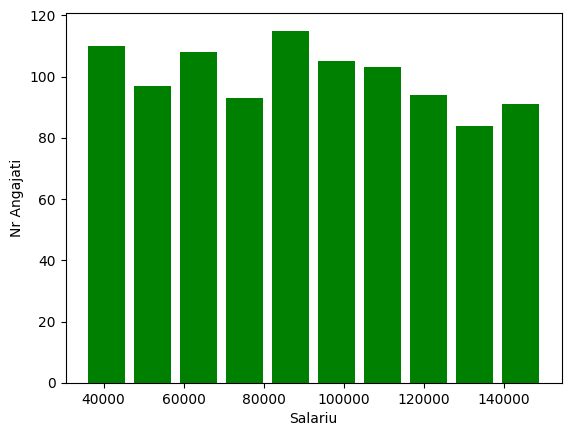

In [3]:
import matplotlib.pyplot as plt

df_employees = get_data_frame('data/employees.csv')

plt.hist(df_employees['Salary'], rwidth=0.8,color='green')
plt.xlabel('Salariu')
plt.ylabel('Nr Angajati')
plt.show()


Distributia salariilor acestor angajati pe categorii de salar si echipa din care fac parte

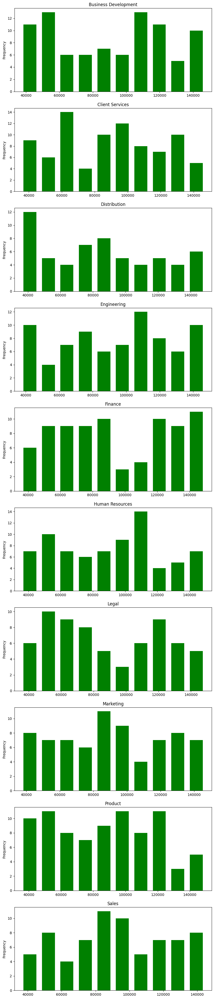

In [19]:
import matplotlib.pyplot as plt

df_employees = get_data_frame('data/employees.csv')
df_filtered_employees = df_employees.dropna()

groups= df_filtered_employees[['Salary','Team']].groupby('Team')

noOfGroups= len(groups) 

figure, axes = plt.subplots(noOfGroups, 1, figsize=(10,50))

for i,(team, group) in enumerate(groups):
    group['Salary'].plot(kind='hist', ax=axes[i], color='green',rwidth=0.7)
    axes[i].set_title(team)

plt.show()

Angajatii care pot fi considerati "outlieri"

In [23]:
q1= df_filtered_employees['Salary'].quantile(0.01)
q2= df_filtered_employees['Salary'].quantile(0.99)

df_filtered_employees[~df_filtered_employees.Salary.between(q1,q2)]


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
63,Matthew,Male,1/2/2013,10:33 PM,35203,18.040,False,Human Resources
82,Steven,Male,3/30/1980,9:20 PM,35095,8.379,True,Client Services
160,Kathy,Female,3/18/2000,7:26 PM,149563,16.991,True,Finance
238,Kevin,Male,3/25/1982,7:31 AM,35061,5.128,False,Legal
318,Roy,Male,8/6/2006,7:52 AM,148225,1.841,False,Finance
429,Rose,Female,5/28/2015,8:40 AM,149903,5.630,False,Human Resources
530,Kathleen,Female,6/13/2014,9:16 AM,35575,14.595,False,Distribution
576,Michael,Male,7/30/1993,5:35 PM,35013,14.879,False,Product
644,Katherine,Female,8/13/1996,12:21 AM,149908,18.912,False,Finance
650,Cynthia,Female,7/5/1986,1:24 AM,35381,11.749,False,Finance


Se dau mai multe imagini (salvate in folder-ul "data/images"). Se cere:

    sa se vizualizeze una din imagini
    daca imaginile nu aceeasi dimensiune, sa se redimensioneze toate la 128 x 128 pixeli si sa se vizualizeze imaginile intr-un cadru tabelar.
    sa se transforme imaginile in format gray-levels si sa se vizualizeze
    sa se blureze o imagine si sa se afiseze in format "before-after"
    sa se identifice muchiile ontr-o imagine si sa se afiseze in format "before-after"

Sa se vizualizeze una din imagini

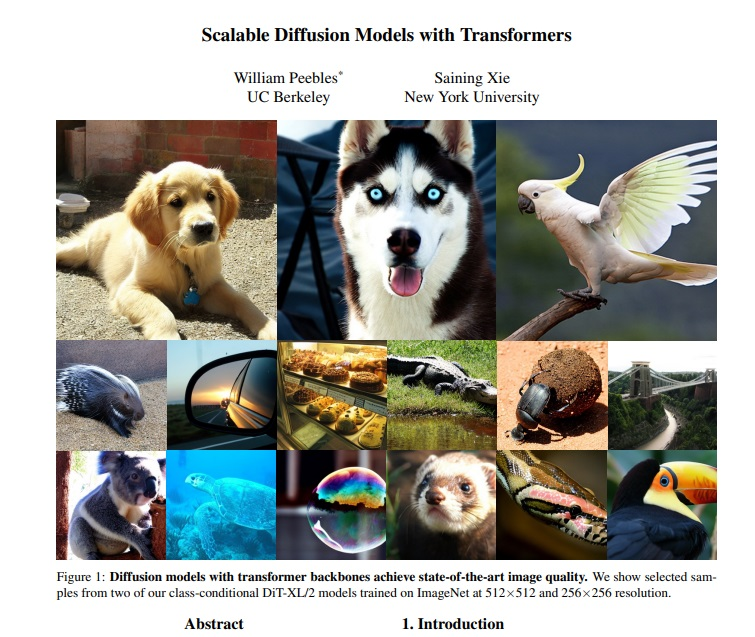

In [2]:
from PIL import Image
import glob, os

with Image.open("data/images/diffusionModel.jpg") as im:
    im.show()

Daca imaginile nu aceeasi dimensiune, sa se redimensioneze toate la 128 x 128 pixeli si sa se vizualizeze imaginile intr-un cadru tabelar

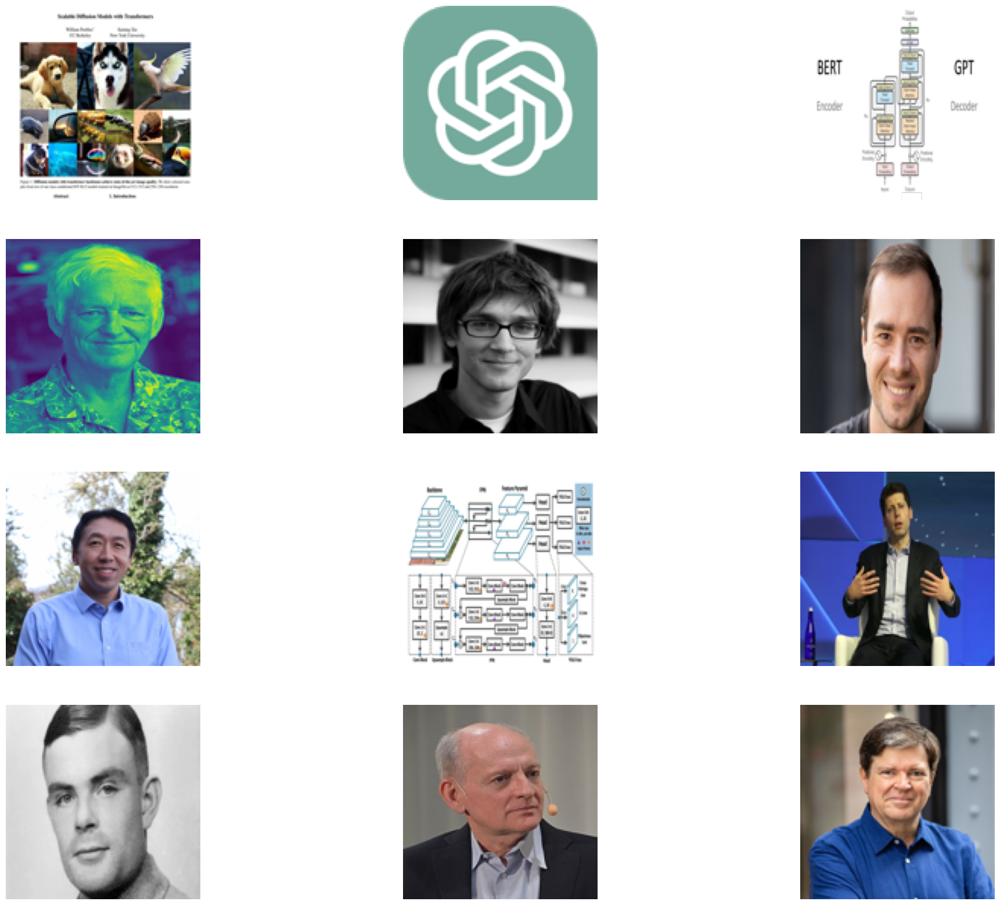

In [4]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

size = 128, 128

imgs = []

fig, axes = plt.subplots(4, 3, figsize=(25,20))

i,j = 0, 0

for infile in glob.glob("data/images/*"):
    if infile.endswith(".png") or infile.endswith(".jpg") or infile.endswith(".webp"):
        with Image.open(infile) as im:
            im_resized = im.resize(size)
            axes[i][j].imshow(im_resized)
            axes[i][j].axis('off')
            j += 1
            if j == 3:
                i, j = i+1, 0

plt.show()

Sa se transforme imaginile in format gray-levels si sa se vizualizeze

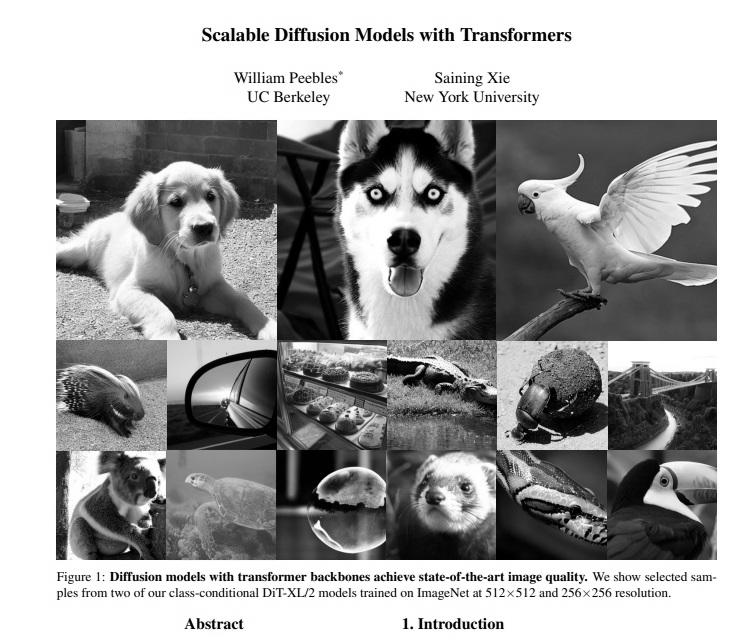

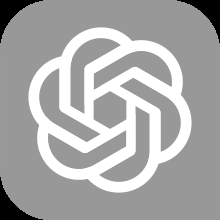

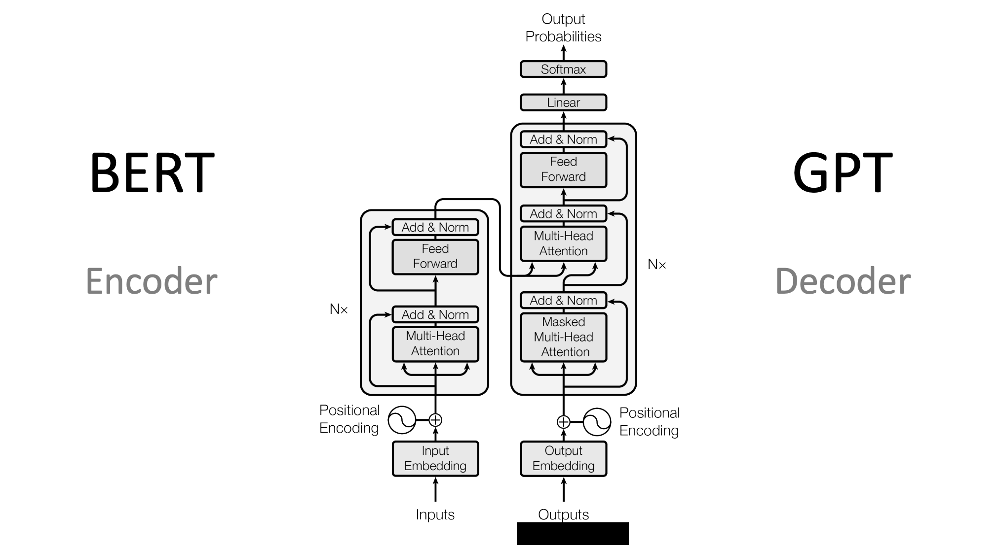

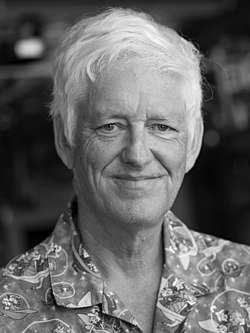

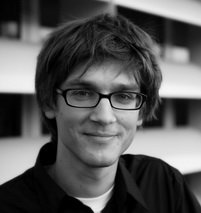

...

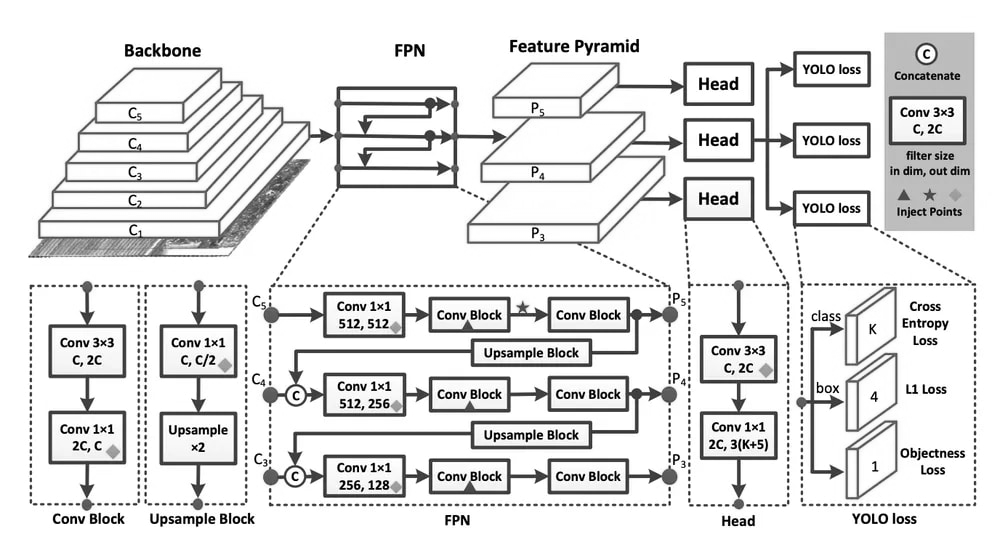

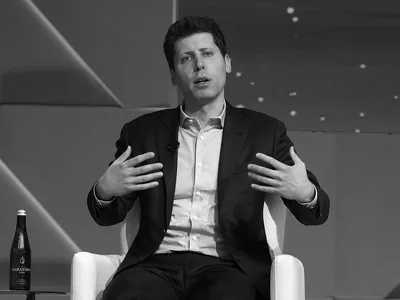

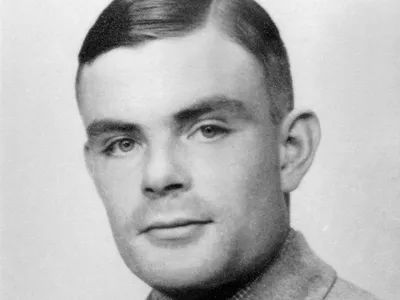

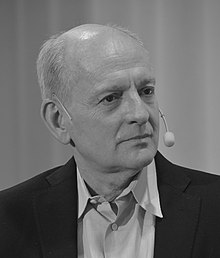

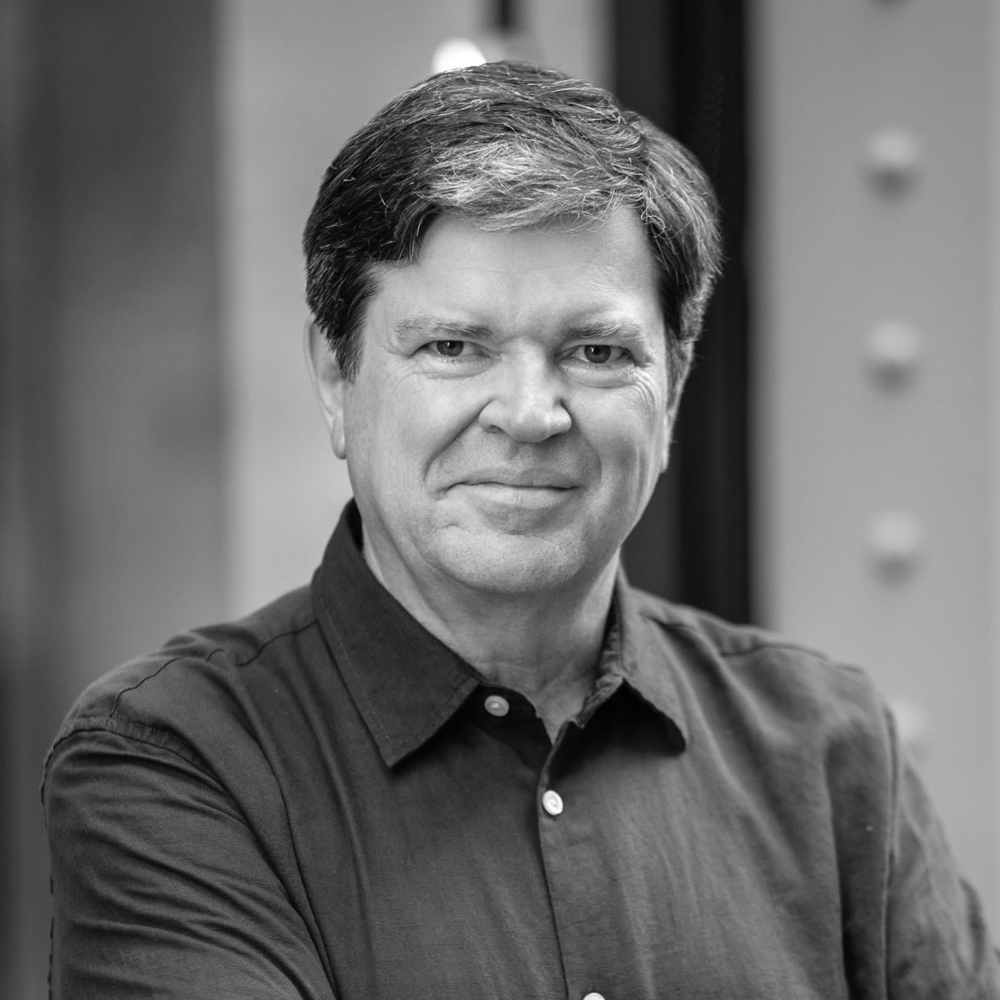

In [4]:
from PIL import ImageOps

for infile in glob.glob("data/images/*"):
    if infile.endswith(".png") or infile.endswith(".jpg") or infile.endswith(".webp"):
        file, ext = os.path.splitext(infile)
        with Image.open(infile) as im:
            gray_im = ImageOps.grayscale(im)
            gray_im.show()

Sa se blureze o imagine si sa se afiseze in format "before-after"

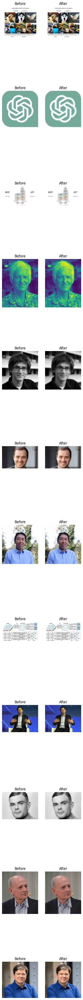

In [4]:
import matplotlib.pyplot as plt
from PIL import ImageFilter

image_paths = []

for infile in glob.glob("data/images/*"):
    if infile.endswith(".png") or infile.endswith(".jpg") or infile.endswith(".webp"):
        file, ext = os.path.splitext(infile)
        image_paths.append(file+ext)

num_images = len(image_paths)
fig, axes = plt.subplots(num_images, 2, figsize=(5,5 * (num_images + 1)))



for i, img_path in enumerate(image_paths):
    original_image = Image.open(img_path)
    blurred_image = original_image.filter(ImageFilter.BLUR)

    axes[i][0].imshow(original_image)
    axes[i][1].imshow(blurred_image)
    
    axes[i][0].axis('off')
    axes[i][1].axis('off')

    axes[i][0].set_title('Before')
    axes[i][1].set_title('After')

plt.show()

Sa se identifice muchiile intr-o imagine si sa se afiseze in format "before-after"

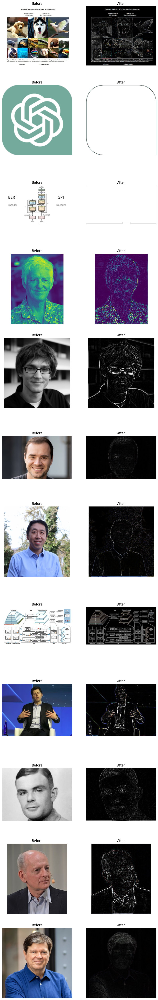

In [5]:
image_paths = []

for infile in glob.glob("data/images/*"):
    if infile.endswith(".png") or infile.endswith(".jpg") or infile.endswith(".webp"):
        file, ext = os.path.splitext(infile)
        image_paths.append(file+ext)

num_images = len(image_paths)
fig, axes = plt.subplots(num_images, 2, figsize=(10,5 * (num_images + 1)))



for i, img_path in enumerate(image_paths):
    original_image = Image.open(img_path)
    blurred_image = original_image.filter(ImageFilter.FIND_EDGES)

    axes[i][0].imshow(original_image)
    axes[i][1].imshow(blurred_image)
    
    axes[i][0].axis('off')
    axes[i][1].axis('off')

    axes[i][0].set_title('Before')
    axes[i][1].set_title('After')

plt.show()

Se da un fisier care contine un text (format din mai multe propozitii) in limba romana - a se vedea fisierul ”data/texts.txt”. Se cere sa se determine si sa se vizualizeze:

    numarul de propozitii din text;
    numarul de cuvinte din text
    numarul de cuvinte diferite din text
    cel mai scurt si cel mai lung cuvant (cuvinte)
    textul fara diacritice
    sinonimele celui mai lung cuvant din text

In [7]:
import nltk

def get_raw_text(path):
    '''
    Citeste textul din fisierul specificat
    path: calea spre fisierul txt
    '''
    file = open(path)
    raw = file.read()
    return raw



Numarul de propozitii din text:

In [5]:
def get_NoOfSentences(raw):
    '''
    Calculeaza numarul de propozitii
    path: calea spre fisierul txt
    '''
    sentences = nltk.sent_tokenize(raw)
    return len(sentences)

print(get_NoOfSentences(get_raw_text('data/texts.txt')))

10


Numarul de cuvinte din text:

In [7]:
def get_NoOfWords(raw):
    '''
    Calculeaza numarul de cuvinte
    path: calea spre fisierul txt
    '''
    words = nltk.word_tokenize(raw)
    words = [word for word in words if word.isalnum()]
    return len(words)

print(get_NoOfWords(get_raw_text('data/texts.txt')))

156


Numarul de cuvinte diferite din text:

In [10]:
def get_NoOfDifferentWords(raw):
    '''
    Calculeaza numarul de cuvinte diferite
    path: calea spre fisierul txt
    '''
    words = nltk.word_tokenize(raw)
    words = [word for word in words if word.isalnum()]
    return len(set(words))
print(get_NoOfDifferentWords(get_raw_text('data/texts.txt')))

94


Cel mai scurt si cel mai lung cuvant (cuvinte)

In [8]:
def get_min_max(raw):
    '''
    Calculeaza cuvantul minim si maxim luat dupa lungimea cuvintelor
    path: calea spre fisierul txt
    '''
    words = nltk.word_tokenize(raw)
    words = [word for word in words if word.isalnum()]
    return min(words, key=len), max(words, key=len)

print(get_min_max(get_raw_text('data/texts.txt')))

('o', 'laboratoarele')


Textul fara diacritice:

In [13]:
from unidecode import unidecode

def get_text_without_diacritics(raw):
    '''
    Returneaza textul fara diacritice
    path: calea spre fisierul txt
    '''
    text = unidecode(raw)
    return text

print(get_text_without_diacritics(get_raw_text('data/texts.txt')))

Mesaj de informare: 
Cursul si laboratoarele de Inteligenta Artificiala vor fi o 
provocare pentru toti. Suntem convinsi ca veti realiza proiecte 
foarte interesante. Va incurajam sa adresati intrebari atunci 
cand ceva nu e clar, atat in mod live, cat si folosind platforma 
Teams, canalul "general". 
Daca ati citit pana aici, va rugam sa lasati un mesaj pe canalul 
general cu textul "Am citit textul pentru problema 3". 
Mesaj de informare generat de ChatGPT:
Stimati cursanti,
Suntem incantati sa va avem in echipa noastra pentru Cursul si 
laboratoarele de Inteligenta Artificiala. Aceasta experienta va 
fi o adevarata provocare, dar suntem convinsi ca veti realiza 
proiecte extrem de interesante.
Va incurajam sa fiti activi si sa adresati intrebari atunci cand 
ceva nu este clar. Fie ca este vorba de o discutie in timp real 
sau prin intermediul platformei Teams, canalul "general", suntem 
aici sa va sprijinim.
Succes si sa inceapa aventura AI!
Cu consideratie, Echipa de Inteligenta Ar

Sinonimele celui mai lung cuvant din text

In [15]:
import rowordnet
import spacy

def remove_suffix(word):
    '''
    Returneaza cuvantul fara sufix
    word: cuvant
    '''
    nlp = spacy.load("ro_core_news_sm")
    doc = nlp(word)
    base_form = doc[0].lemma_
    return base_form

def get_synonyms(word):
    '''
    Returneaza sinonimele cuvintelor
    word: 
    '''
    wn = rowordnet.RoWordNet()

    word = remove_suffix(word)
    synonyms = []
    synsets_id = wn.synsets(literal=word)
    for synset_id in synsets_id:
        synset = wn(synset_id)
        literals = list(synset.literals)
        for i in range(len(literals)):
            for j in range(i+1, len(literals)):
                synonyms.append((literals[i], literals[j]))
    return synonyms
def get_synonym_longest_word(raw):
    '''
    Gaseste sinonimele celui mai lung cuvant
    raw: text
    '''
    min_word, max_word = get_min_max(raw)
    synonyms = get_synonyms(remove_suffix(max_word))
    return synonyms

synonyms = get_synonym_longest_word(get_raw_text('data/texts.txt'))
for i in range(len(synonyms)):
     print("{:>25} == {}".format(synonyms[i][0], synonyms[i][1]))   

                laborator == poligon_de_încercare
                laborator == laborator_de_cercetare
                laborator == laborator_de_științe
   laborator_de_cercetare == laborator_de_științe
                laborator == laborator_de_cercetare
                laborator == laborator_de_științe
   laborator_de_cercetare == laborator_de_științe
                laborator == laborator_de_cercetare
                laborator == laborator_de_științe
   laborator_de_cercetare == laborator_de_științe


Sa se normalizeze informatiile de la problema 1 si 2 folosind diferite metode de normalizare astfel:

    problema 1 - salariul, bonusul, echipa
    problema 2 - valorile pixelilor din imagini
    problema 3 - numarul de aparitii a cuvintelor la nivelul unei propozitii.

Problema 1

Salariul:

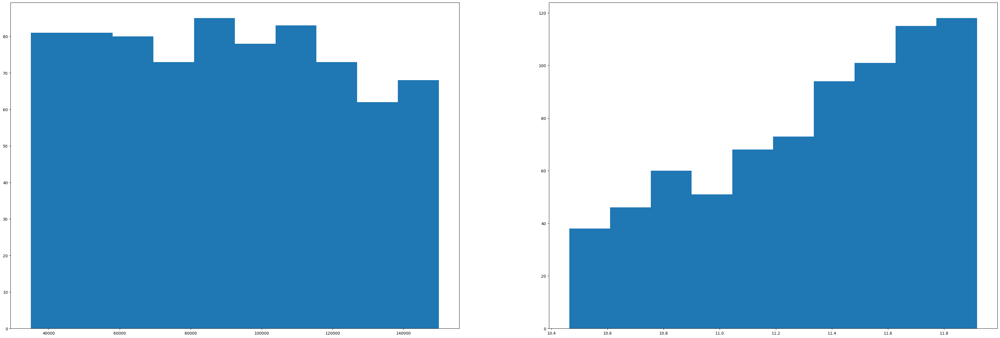

In [49]:
import matplotlib.pyplot as plt
from math import log

valori = df_employees.dropna()['Salary']

valoriLog = [log(v) for v in valori]

figure, (ax1,ax2) = plt.subplots(1,2, figsize=(45,15))

ax1.hist(valori)
ax2.hist(valoriLog)


plt.show()

Bonusul:

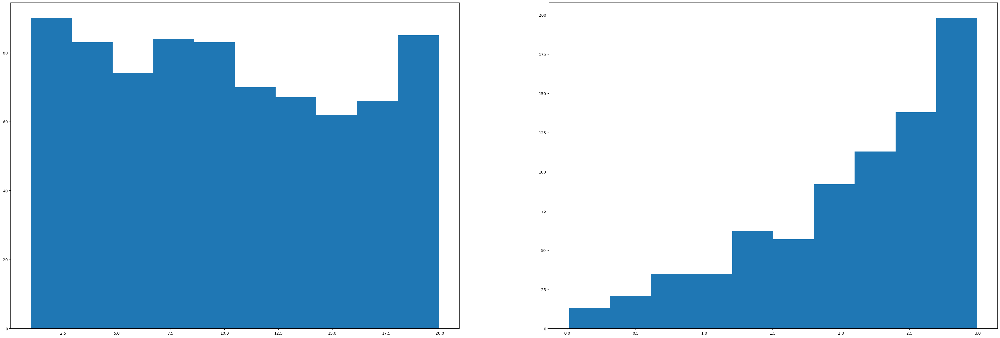

In [50]:
import matplotlib.pyplot as plt
from math import log

valori = df_employees.dropna()['Bonus %']

valoriLog = [log(v) for v in valori]

figure, (ax1,ax2) = plt.subplots(1,2, figsize=(45,15))

ax1.hist(valori)
ax2.hist(valoriLog)


plt.show()

Echipa:

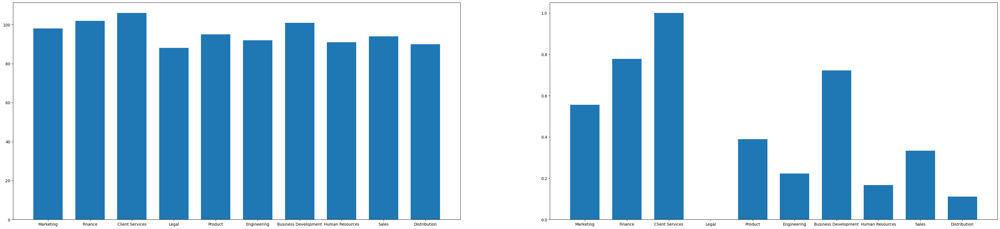

In [15]:
import matplotlib.pyplot as plt

valori = df_employees.dropna()['Team'].unique()

count = []
for v in valori:
    count.append(df_employees[df_employees['Team']==v].shape[0])

mini, maxi = min(count), max(count)

count2 = []
for i in range(len(count)):
    count2.append((count[i] - mini) / (maxi - mini))

# plt.figure(figsize=(25,10))

figure, (ax1,ax2) = plt.subplots(1,2, figsize=(45,10))

ax1.bar(range(len(valori)), count, align='center', width=0.7)
ax1.set_xticks(range(len(valori)),valori)


ax2.bar(range(len(valori)), count2, align='center', width=0.7)
ax2.set_xticks(range(len(valori)),valori)

plt.show()

Problema 2

Valorile pixelilor din imagine:

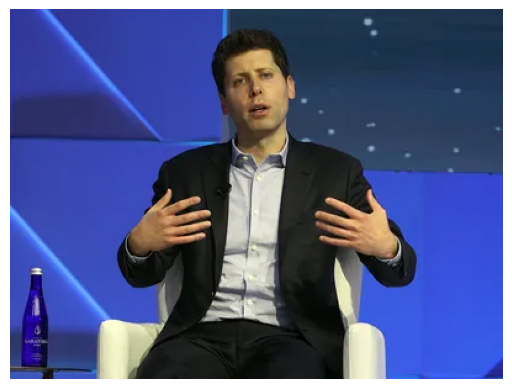

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


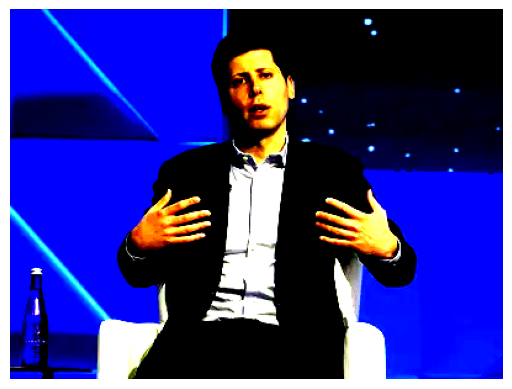

In [10]:
import numpy as np
from PIL import Image

def show_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

def norm_min_max(image):
    return (image - np.min(image)) / (np.max(image) - np.min(image))

def norm_z_norm(image):
    mean_val = np.mean(image)
    std_val = np.std(image)
    return (image - mean_val)/std_val

image = Image.open('data/images/Altman.webp')

show_image(norm_min_max(image))
show_image(norm_z_norm(image))

Problema 3

L2 Normalization

In [16]:
import nltk
from math import sqrt

file = open('data/texts.txt')
raw = file.read()

def L2_normalization(text):

    words = nltk.word_tokenize(text)
    words = [word for word in words if word.isalnum()]

    dict = {}

    for word in words:
        if word in dict.keys():
            dict[word] += 1
        else:
            dict[word] = 1
    
    l2Norm = 0
    for val in dict.values():
        l2Norm += val ** 2
    
    l2Norm = sqrt(l2Norm)

    for word in dict.keys():
        dict[word] = dict[word] / l2Norm
    
    return dict

L2_normalization(raw)


{'Mesaj': 0.10232890201933016,
 'de': 0.40931560807732065,
 'informare': 0.10232890201933016,
 'Cursul': 0.10232890201933016,
 'și': 0.2558222550483254,
 'laboratoarele': 0.10232890201933016,
 'Inteligență': 0.15349335302899525,
 'Artificială': 0.15349335302899525,
 'vor': 0.05116445100966508,
 'fi': 0.10232890201933016,
 'o': 0.15349335302899525,
 'provocare': 0.10232890201933016,
 'pentru': 0.15349335302899525,
 'toți': 0.05116445100966508,
 'Suntem': 0.10232890201933016,
 'convinși': 0.10232890201933016,
 'că': 0.15349335302899525,
 'veți': 0.10232890201933016,
 'realiza': 0.10232890201933016,
 'proiecte': 0.10232890201933016,
 'foarte': 0.05116445100966508,
 'interesante': 0.10232890201933016,
 'Vă': 0.10232890201933016,
 'încurajăm': 0.10232890201933016,
 'să': 0.3581511570676556,
 'adresați': 0.10232890201933016,
 'întrebări': 0.10232890201933016,
 'atunci': 0.10232890201933016,
 'când': 0.10232890201933016,
 'ceva': 0.10232890201933016,
 'nu': 0.10232890201933016,
 'e': 0.051164